In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
# 1. Wczytanie danych
# Upewnij się, że plik 'wine.csv' znajduje się w tym samym folderze co skrypt
wine_df = pd.read_csv('wine.csv')

In [3]:
# 2. Definicja X i Y dla Wine
X_wine = wine_df[['Alcohol', 'Phenols']].values
y_wine = wine_df['Wine'].values

In [4]:
# 3. Podział na zbiór treningowy i testowy (30% test)
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(X_wine, y_wine, test_size=0.30, random_state=42)

In [5]:
# 4. Skalowanie cech (bardzo ważne w algorytmach SVM)
sc_w = StandardScaler()
X_train_w = sc_w.fit_transform(X_train_w)
X_test_w = sc_w.transform(X_test_w)

In [6]:
# Lista jąder (kernels) do przetestowania
kernels = ['linear', 'rbf', 'poly', 'sigmoid']

best_acc_w = 0
best_kernel_w = ''

In [7]:
print("--- ANALIZA DLA ZBIORU WINE ---")
for kernel in kernels:
    # 5. Dopasowanie modelu
    classifier = SVC(kernel=kernel, random_state=42)
    classifier.fit(X_train_w, y_train_w)

    # 6. Przewidywania
    y_pred_test = classifier.predict(X_test_w)
    y_pred_train = classifier.predict(X_train_w)

    # 7. Macierze zmieszania i dokładność (Accuracy)
    cm_test = confusion_matrix(y_test_w, y_pred_test)
    acc_test = accuracy_score(y_test_w, y_pred_test)
    acc_train = accuracy_score(y_train_w, y_pred_train)

    print(f"\nKernel: {kernel}")
    print(f"Accuracy Train: {acc_train:.4f}")
    print(f"Accuracy Test: {acc_test:.4f}")

    # Szukamy jądra z najlepszym wynikiem na zbiorze testowym
    if acc_test > best_acc_w:
        best_acc_w = acc_test
        best_kernel_w = kernel

--- ANALIZA DLA ZBIORU WINE ---

Kernel: linear
Accuracy Train: 0.8548
Accuracy Test: 0.8704

Kernel: rbf
Accuracy Train: 0.8548
Accuracy Test: 0.8704

Kernel: poly
Accuracy Train: 0.7339
Accuracy Test: 0.8148

Kernel: sigmoid
Accuracy Train: 0.8226
Accuracy Test: 0.8333


In [8]:
print(f"\nNajlepsze jądro (kernel) dla Wine: {best_kernel_w} z wynikiem (Test Acc): {best_acc_w:.4f}")



Najlepsze jądro (kernel) dla Wine: linear z wynikiem (Test Acc): 0.8704


In [9]:
# --- WIZUALIZACJA DLA NAJLEPSZEGO JĄDRA ---
# Trenujemy ostateczny model na najlepszym jądrze do wizualizacji
classifier_best = SVC(kernel=best_kernel_w, random_state=42)
classifier_best.fit(X_train_w, y_train_w)


def plot_decision_regions(X, y, classifier, title):
    # Tworzenie siatki (mesh)
    X1, X2 = np.meshgrid(np.arange(start=X[:, 0].min() - 1, stop=X[:, 0].max() + 1, step=0.01),
                         np.arange(start=X[:, 1].min() - 1, stop=X[:, 1].max() + 1, step=0.01))

    # Rysowanie tła (obszarów decyzyjnych)
    plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
                 alpha=0.75, cmap=ListedColormap(('red', 'green', 'blue')))
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())

    # Rysowanie punktów
    for i, j in enumerate(np.unique(y)):
        plt.scatter(X[y == j, 0], X[y == j, 1],
                    color=ListedColormap(('darkred', 'darkgreen', 'darkblue'))(i), label=j)

    plt.title(title)
    plt.xlabel('Alcohol (scalone)')
    plt.ylabel('Phenols (scalone)')
    plt.legend()
    plt.show()

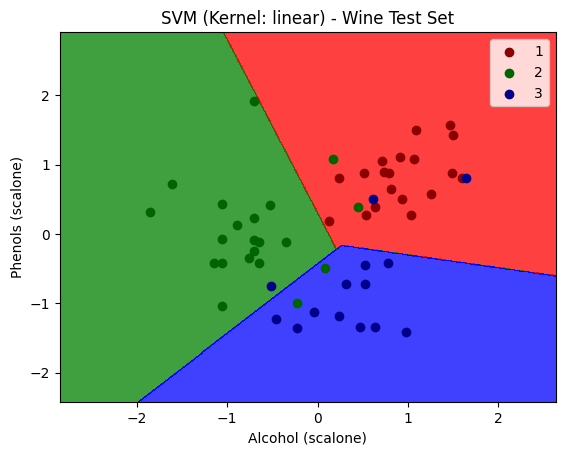

In [10]:
# Wizualizacja zbioru testowego dla Wine
plot_decision_regions(X_test_w, y_test_w, classifier_best, f'SVM (Kernel: {best_kernel_w}) - Wine Test Set')